# Inside India's UPI Economy
### A Business Analytics Case Study

**Project Overview**

This project analyzes India's Unified Payments Interface (UPI) ecosystem to understand market growth, payment app competition, and regional transaction patterns.

The analysis uses three datasets covering overall UPI statistics, app-wise transactions, and state-wise transactions.

**Business Questions**

1. How is India's UPI market changing over time?
2. How do major UPI payment apps compare in transaction activity?
3. Which states and union territories have the highest UPI activity and growth?
4. What potential business opportunities can be identified from these trends?

**Tools and Technologies**

- Python
- Google Colab
- Pandas
- NumPy
- Matplotlib
- Seaborn

**Project Type:** Business Analytics | Exploratory Data Analysis

## 1. Importing Libraries and Loading App-wise Data

In [74]:
from google.colab import files
uploaded = files.upload()

Saving npci-upi-apps.csv to npci-upi-apps (1).csv


In [75]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("npci-upi-apps.csv")

print(df.shape)

(69, 1616)


In [76]:
df.head()

,date,"Aditya Birla Capital Digital, business to business (value)","Aditya Birla Capital Digital, business to business (number)","Aditya Birla Capital Digital, business to customer (value)","Aditya Birla Capital Digital, business to customer (number)","Aditya Birla Capital Digital, started by customers (value)","Aditya Birla Capital Digital, started by customers (number)","Aditya Birla Capital Digital, on-us (value, printed beside the total)","Aditya Birla Capital Digital, on-us, payer and payee on the same bank's app (number, printed beside the total)","Aditya Birla Capital Digital, all transactions (value)",...,"ZET, all transactions (value)","ZET, all transactions (number)","ZOICICI, started by customers (value)","ZOICICI, started by customers (number)","ZOICICI, all transactions (value)","ZOICICI, all transactions (number)","Zomato, started by customers (value)","Zomato, started by customers (number)","Zomato, all transactions (value)","Zomato, all transactions (number)"
0,2020-12-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2021-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2021-02-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2021-03-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2021-04-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [77]:
for col in df.columns[:20]:
    print(col)

date
Aditya Birla Capital Digital, business to business (value)
Aditya Birla Capital Digital, business to business (number)
Aditya Birla Capital Digital, business to customer (value)
Aditya Birla Capital Digital, business to customer (number)
Aditya Birla Capital Digital, started by customers (value)
Aditya Birla Capital Digital, started by customers (number)
Aditya Birla Capital Digital, on-us (value, printed beside the total)
Aditya Birla Capital Digital, on-us, payer and payee on the same bank's app (number, printed beside the total)
Aditya Birla Capital Digital, all transactions (value)
Aditya Birla Capital Digital, all transactions (number)
Aditya Birla Capital Digital Limited, started by customers (value)
Aditya Birla Capital Digital Limited, started by customers (number)
Aditya Birla Capital Digital Limited, all transactions (value)
Aditya Birla Capital Digital Limited, all transactions (number)
Airtel Payments Bank apps, business to business (value)
Airtel Payments Bank apps, b

In [78]:
print("Total columns:", len(df.columns))

print("Total unique column names:", df.columns.nunique())

print("Date column:", df.columns[0])

Total columns: 1616
Total unique column names: 1616
Date column: date


In [79]:
print(df["date"].min())
print(df["date"].max())

2020-12-01
2026-08-01


In [80]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 69 entries, 0 to 68
Columns: 1616 entries, date to Zomato, all transactions (number)
dtypes: float64(1559), int64(56), object(1)
memory usage: 871.3+ KB


In [81]:
missing_values = df.isnull().sum().sum()

print("Total missing values:", missing_values)

Total missing values: 83569


In [82]:
print("Total cells:", df.size)
print("Missing percentage:",
      round((missing_values / df.size) * 100, 2), "%")

Total cells: 111504
Missing percentage: 74.95 %


In [83]:
missing_by_column = df.isnull().sum()

missing_by_column.sort_values(
    ascending=False
).head(20)

,0
"Aditya Birla Capital Digital Limited, started by customers (value)",68
"Aditya Birla Capital Digital Limited, started by customers (number)",68
"Aditya Birla Capital Digital Limited, all transactions (value)",68
"Aditya Birla Capital Digital Limited, all transactions (number)",68
"Omnicard PPI, started by customers (value)",68
"Omnicard PPI, started by customers (number)",68
"Omnicard PPI, all transactions (value)",68
"Omnicard PPI, all transactions (number)",68
"Other, started by customers (value)",68
"Other, started by customers (number)",68


In [84]:
col = "Aditya Birla Capital Digital Limited, all transactions (number)"

print(df[["date", col]].to_string(index=False))

      date  Aditya Birla Capital Digital Limited, all transactions (number)
2020-12-01                                                              NaN
2021-01-01                                                              NaN
2021-02-01                                                              NaN
2021-03-01                                                              NaN
2021-04-01                                                              NaN
2021-05-01                                                              NaN
2021-06-01                                                              NaN
2021-07-01                                                              NaN
2021-08-01                                                              NaN
2021-09-01                                                              NaN
2021-10-01                                                              NaN
2021-11-01                                                              NaN
2021-12-01  

In [85]:
reported_months = df.notnull().sum()

reported_months.sort_values(
    ascending=False
).head(20)

,0
"Yes Bank apps, all transactions (value)",69
date,69
"Yes Bank apps, started by customers (number)",69
"Yes Bank apps, started by customers (value)",69
"Airtel Payments Bank apps, all transactions (number)",69
"Kotak Mahindra Bank apps, all transactions (number)",69
"Kotak Mahindra Bank apps, all transactions (value)",69
"Kotak Mahindra Bank apps, started by customers (value)",69
"Kotak Mahindra Bank apps, started by customers (number)",69
"WhatsApp, all transactions (number)",69


In [86]:
complete_columns = (df.notnull().sum() == len(df)).sum()

print("Columns with complete data:", complete_columns)
print("Total columns:", len(df.columns))

Columns with complete data: 57
Total columns: 1616


In [87]:
coverage = (df.notnull().sum() / len(df)) * 100

print(coverage.describe())

count    1616.000000
mean       25.052913
std        26.838856
min         1.449275
25%         4.347826
50%        20.289855
75%        27.536232
max       100.000000
dtype: float64


In [88]:
# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Convert date column to datetime
df["date"] = pd.to_datetime(df["date"], errors="coerce")

# Check transaction column data types
transaction_columns = [
    "PhonePe, all transactions (number)",
    "Google Pay, all transactions (number)",
    "Paytm, all transactions (number)"
]

for col in transaction_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("\nData types after cleaning:")
print(df[["date"] + transaction_columns].dtypes)

print("\nMissing values in selected columns:")
print(df[["date"] + transaction_columns].isnull().sum())

Duplicate rows: 0

Data types after cleaning:
date                                     datetime64[ns]
PhonePe, all transactions (number)                int64
Google Pay, all transactions (number)             int64
Paytm, all transactions (number)                float64
dtype: object

Missing values in selected columns:
date                                      0
PhonePe, all transactions (number)        0
Google Pay, all transactions (number)     0
Paytm, all transactions (number)         38
dtype: int64


In [89]:
coverage_table = pd.DataFrame({
    "column": df.columns,
    "reported_months": df.notnull().sum().values,
    "coverage_percentage": coverage.values
})

coverage_table = coverage_table[
    coverage_table["coverage_percentage"] >= 80
]

coverage_table.sort_values(
    "coverage_percentage",
    ascending=False
)

,column,reported_months,coverage_percentage
0,date,69,100.000000
19,"Airtel Payments Bank apps, started by customer...",69,100.000000
20,"Airtel Payments Bank apps, started by customer...",69,100.000000
23,"Airtel Payments Bank apps, all transactions (v...",69,100.000000
24,"Airtel Payments Bank apps, all transactions (n...",69,100.000000
...,...,...,...
1124,"PhonePe, all transactions (value)",66,95.652174
1523,"Ultracash, all transactions (number)",66,95.652174
1518,"Ultracash, started by customers (value)",66,95.652174
1522,"Ultracash, all transactions (value)",66,95.652174


In [90]:
number_columns = coverage_table[
    (coverage_table["coverage_percentage"] >= 80) &
    (coverage_table["column"].str.contains(
        "all transactions (number)",
        case=False,
        regex=False
    ))
]

print(number_columns.to_string(index=False))

                                              column  reported_months  coverage_percentage
Airtel Payments Bank apps, all transactions (number)               69           100.000000
               Amazon Pay, all transactions (number)               69           100.000000
           Axis Bank apps, all transactions (number)               69           100.000000
            Bajaj Finserv, all transactions (number)               68            98.550725
      Bank of Baroda apps, all transactions (number)               69           100.000000
                     BHIM, all transactions (number)               69           100.000000
                     CRED, all transactions (number)               69           100.000000
               Google Pay, all transactions (number)               69           100.000000
           HDFC Bank apps, all transactions (number)               69           100.000000
          ICICI Bank apps, all transactions (number)               69           100.000000

## 2. App-wise UPI Competition Analysis

In [91]:
selected_columns = [
    "date",
    "PhonePe, all transactions (number)",
    "Google Pay, all transactions (number)",
    "Paytm, all transactions (number)"
]

upi_compare = df[selected_columns].copy()

upi_compare.head(10)

,date,"PhonePe, all transactions (number)","Google Pay, all transactions (number)","Paytm, all transactions (number)"
0,2020-12-01,902030000,854490000,NaN
1,2021-01-01,968720000,853530000,NaN
2,2021-02-01,975530000,827860000,NaN
3,2021-03-01,1199510000,957010000,NaN
4,2021-04-01,1189890000,905960000,NaN
5,2021-05-01,1149840000,880590000,NaN
6,2021-06-01,1292710000,972260000,NaN
7,2021-07-01,1492090000,1119160000,NaN
8,2021-08-01,1622950000,1243750000,NaN
9,2021-09-01,1653190000,1294560000,NaN


In [92]:
print(upi_compare.isnull().sum())

date                                      0
PhonePe, all transactions (number)        0
Google Pay, all transactions (number)     0
Paytm, all transactions (number)         38
dtype: int64


In [93]:
upi_compare.tail(10)

,date,"PhonePe, all transactions (number)","Google Pay, all transactions (number)","Paytm, all transactions (number)"
59,2025-11-01,9322290000,7020940000,1.518950e+09
60,2025-12-01,9799140000,7311670000,1.624450e+09
61,2026-01-01,9913630000,7229110000,1.659490e+09
62,2026-02-01,9284220000,6767140000,1.595090e+09
63,2026-03-01,10503810000,7535710000,1.770000e+09
64,2026-04-01,10330303979,7359444662,1.778060e+09
65,2026-05-01,10734583524,7598365549,1.836023e+09
66,2026-06-01,10483728651,7407712634,1.798836e+09
67,2026-07-01,10857910000,7649820000,1.903870e+09
68,2026-08-01,11185100622,7907379297,1.967895e+09


In [94]:
paytm_data = upi_compare[
    upi_compare["Paytm, all transactions (number)"].notnull()
]

print("First reported month:")
print(paytm_data["date"].min())

print("Last reported month:")
print(paytm_data["date"].max())

print("Total reported months:")
print(len(paytm_data))

First reported month:
2024-02-01 00:00:00
Last reported month:
2026-08-01 00:00:00
Total reported months:
31


In [95]:
fair_compare = upi_compare.dropna().copy()

print("Comparison period:")
print(fair_compare["date"].min())
print(fair_compare["date"].max())

print("Number of months:", len(fair_compare))

fair_compare.head()

Comparison period:
2024-02-01 00:00:00
2026-08-01 00:00:00
Number of months: 31


,date,"PhonePe, all transactions (number)","Google Pay, all transactions (number)","Paytm, all transactions (number)"
38,2024-02-01,5760010000,4508120000,1.340350e+09
39,2024-03-01,6502150000,5061180000,1.230040e+09
40,2024-04-01,6500140000,5027320000,1.117130e+09
41,2024-05-01,6831920000,5219560000,1.140010e+09
42,2024-06-01,6716090000,5103990000,1.104890e+09


In [96]:
app_totals = fair_compare[
    [
        "PhonePe, all transactions (number)",
        "Google Pay, all transactions (number)",
        "Paytm, all transactions (number)"
    ]
].sum()

print(app_totals)

PhonePe, all transactions (number)       2.659124e+11
Google Pay, all transactions (number)    1.997192e+11
Paytm, all transactions (number)         4.292458e+10
dtype: float64


In [97]:
market_share = (app_totals / app_totals.sum()) * 100

print(market_share.round(2))

PhonePe, all transactions (number)       52.29
Google Pay, all transactions (number)    39.27
Paytm, all transactions (number)          8.44
dtype: float64


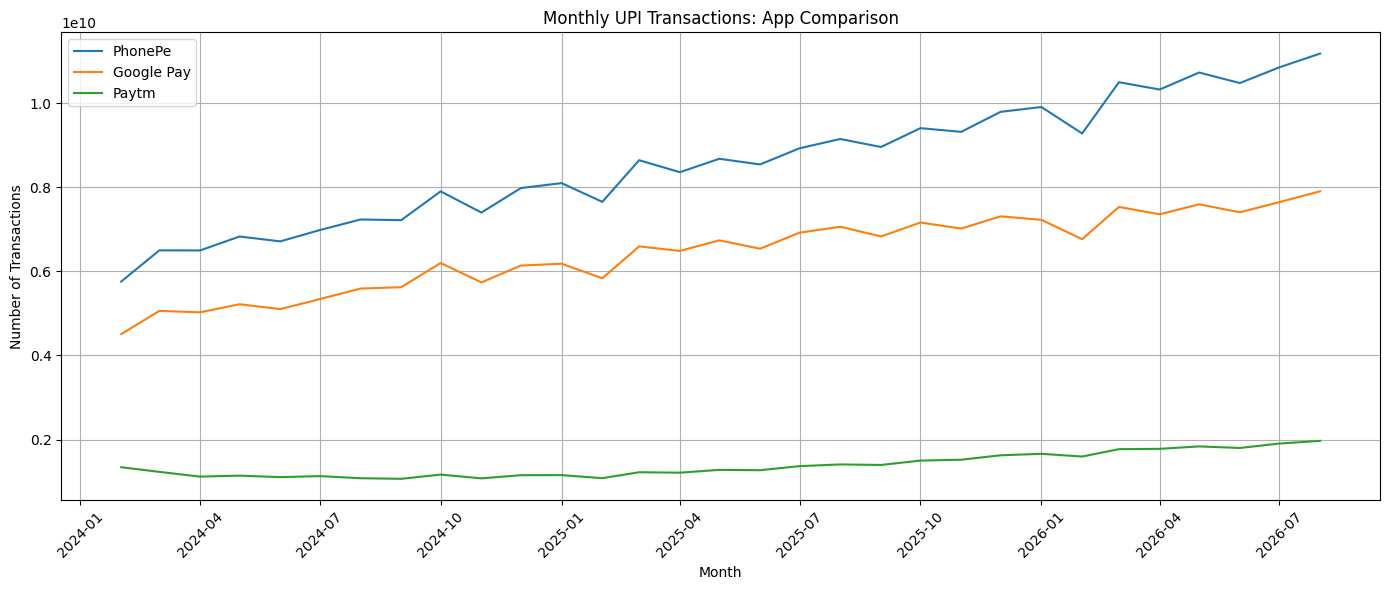

In [98]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    fair_compare["date"],
    fair_compare["PhonePe, all transactions (number)"],
    label="PhonePe"
)

plt.plot(
    fair_compare["date"],
    fair_compare["Google Pay, all transactions (number)"],
    label="Google Pay"
)

plt.plot(
    fair_compare["date"],
    fair_compare["Paytm, all transactions (number)"],
    label="Paytm"
)

plt.title("Monthly UPI Transactions: App Comparison")
plt.xlabel("Month")
plt.ylabel("Number of Transactions")
plt.legend()
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [99]:
growth = {}

for col in [
    "PhonePe, all transactions (number)",
    "Google Pay, all transactions (number)",
    "Paytm, all transactions (number)"
]:
    start = fair_compare[col].iloc[0]
    end = fair_compare[col].iloc[-1]

    growth[col] = ((end - start) / start) * 100

growth = pd.Series(growth)

print("Growth percentage:")
print(growth.round(2))

Growth percentage:
PhonePe, all transactions (number)       94.19
Google Pay, all transactions (number)    75.40
Paytm, all transactions (number)         46.82
dtype: float64


In [100]:
monthly_change = fair_compare.copy()

apps = [
    "PhonePe, all transactions (number)",
    "Google Pay, all transactions (number)",
    "Paytm, all transactions (number)"
]

for app in apps:
    monthly_change[app + " growth"] = (
        monthly_change[app].pct_change() * 100
    )

monthly_change[
    ["date"] + [app + " growth" for app in apps]
].tail(12).round(2)

,date,"PhonePe, all transactions (number) growth","Google Pay, all transactions (number) growth","Paytm, all transactions (number) growth"
57,2025-09-01,-2.08,-3.27,-0.94
58,2025-10-01,5.01,4.85,7.49
59,2025-11-01,-0.94,-2.00,1.36
60,2025-12-01,5.12,4.14,6.95
61,2026-01-01,1.17,-1.13,2.16
62,2026-02-01,-6.35,-6.39,-3.88
63,2026-03-01,13.14,11.36,10.97
64,2026-04-01,-1.65,-2.34,0.46
65,2026-05-01,3.91,3.25,3.26
66,2026-06-01,-2.34,-2.51,-2.03


In [101]:
fair_compare["combined_transactions"] = (
    fair_compare[
        [
            "PhonePe, all transactions (number)",
            "Google Pay, all transactions (number)",
            "Paytm, all transactions (number)"
        ]
    ].sum(axis=1)
)

fair_compare[
    ["date", "combined_transactions"]
].tail(12)

,date,combined_transactions
57,2025-09-01,1.718878e+10
58,2025-10-01,1.807352e+10
59,2025-11-01,1.786218e+10
60,2025-12-01,1.873526e+10
61,2026-01-01,1.880223e+10
62,2026-02-01,1.764645e+10
63,2026-03-01,1.980952e+10
64,2026-04-01,1.946781e+10
65,2026-05-01,2.016897e+10
66,2026-06-01,1.969028e+10


In [102]:
fair_compare["combined_growth"] = (
    fair_compare["combined_transactions"].pct_change() * 100
)

fair_compare[
    ["date", "combined_transactions", "combined_growth"]
].tail(12).round(2)

,date,combined_transactions,combined_growth
57,2025-09-01,1.718878e+10,-2.47
58,2025-10-01,1.807352e+10,5.15
59,2025-11-01,1.786218e+10,-1.17
60,2025-12-01,1.873526e+10,4.89
61,2026-01-01,1.880223e+10,0.36
62,2026-02-01,1.764645e+10,-6.15
63,2026-03-01,1.980952e+10,12.26
64,2026-04-01,1.946781e+10,-1.72
65,2026-05-01,2.016897e+10,3.60
66,2026-06-01,1.969028e+10,-2.37


In [103]:
fair_compare["month"] = pd.to_datetime(
    fair_compare["date"]
).dt.month

monthly_pattern = fair_compare.groupby("month")[
    "combined_transactions"
].mean()

print(monthly_pattern)

month
1     1.712046e+10
2     1.460926e+10
3     1.635618e+10
4     1.605783e+10
5     1.668684e+10
6     1.632412e+10
7     1.702866e+10
8     1.753058e+10
9     1.554992e+10
10    1.667294e+10
11    1.603916e+10
12    1.700537e+10
Name: combined_transactions, dtype: float64


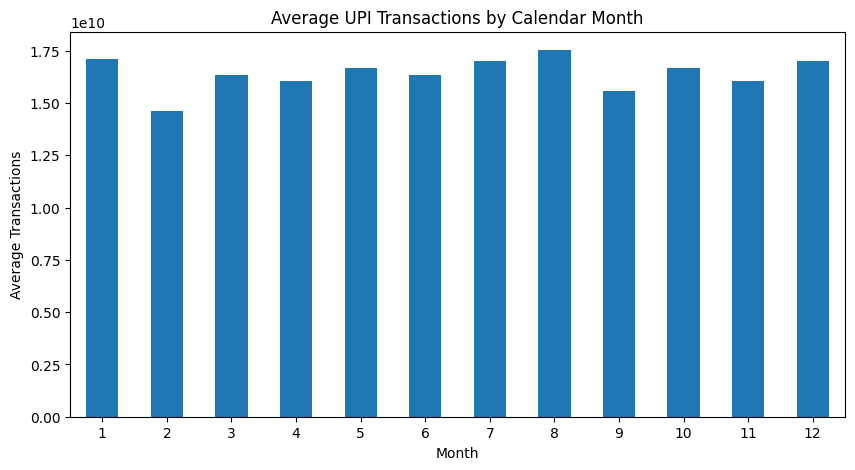

In [104]:
monthly_pattern.plot(
    kind="bar",
    figsize=(10, 5),
    title="Average UPI Transactions by Calendar Month"
)

plt.xlabel("Month")
plt.ylabel("Average Transactions")
plt.xticks(rotation=0)
plt.show()

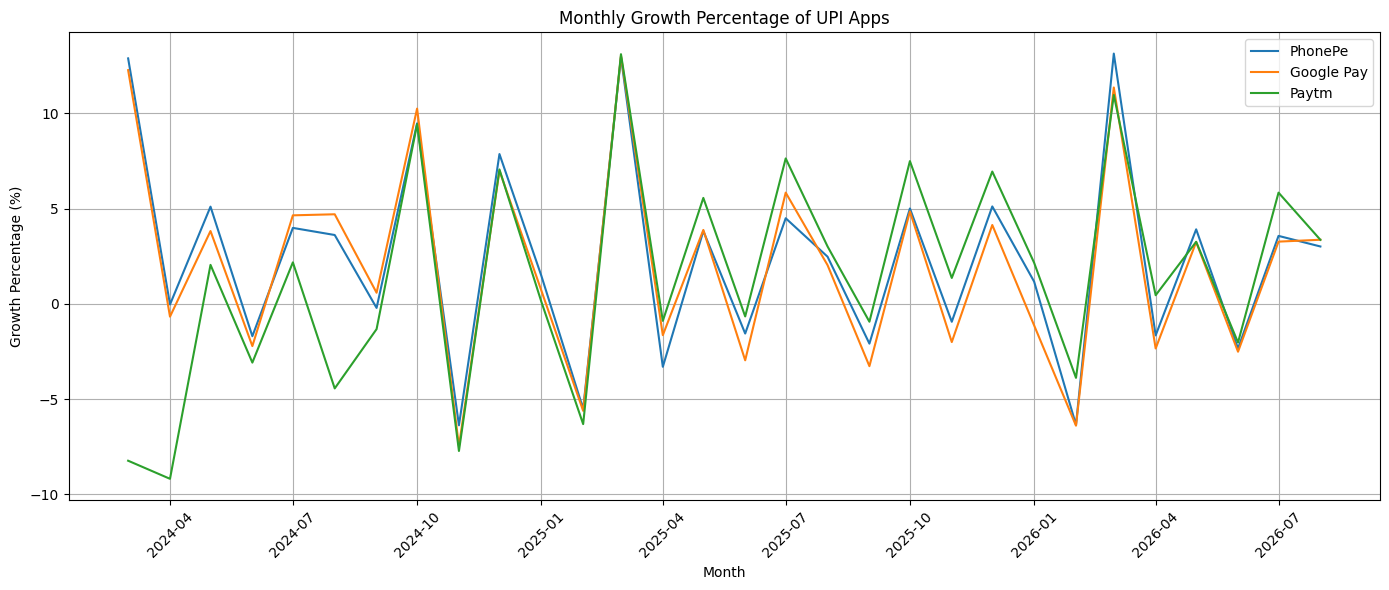

In [105]:
plt.figure(figsize=(14, 6))

for app in apps:
    plt.plot(
        monthly_change["date"],
        monthly_change[app + " growth"],
        label=app.split(",")[0]
    )

plt.title("Monthly Growth Percentage of UPI Apps")
plt.xlabel("Month")
plt.ylabel("Growth Percentage (%)")
plt.legend()
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

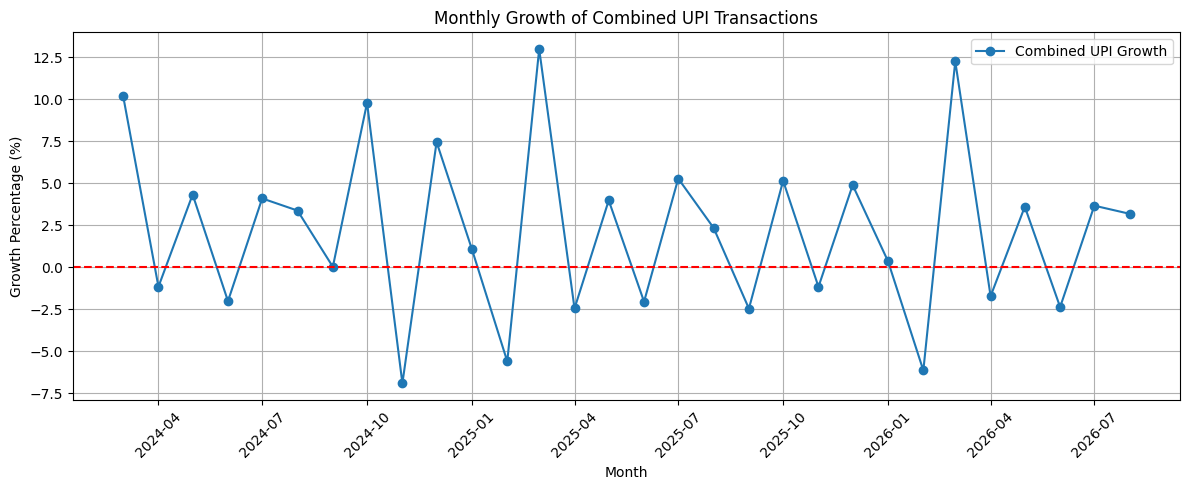

In [106]:
plt.figure(figsize=(12, 5))

plt.plot(
    fair_compare["date"],
    fair_compare["combined_growth"],
    marker="o",
    label="Combined UPI Growth"
)

plt.title("Monthly Growth of Combined UPI Transactions")
plt.xlabel("Month")
plt.ylabel("Growth Percentage (%)")
plt.xticks(rotation=45)
plt.axhline(y=0, color="red", linestyle="--")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

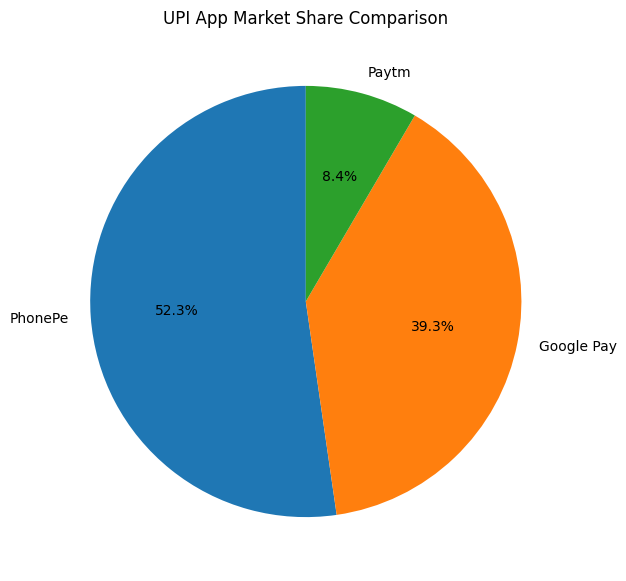

In [107]:
plt.figure(figsize=(7, 7))

plt.pie(
    app_totals,
    labels=["PhonePe", "Google Pay", "Paytm"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("UPI App Market Share Comparison")
plt.show()

In [108]:
summary = pd.DataFrame({
    "UPI App": ["PhonePe", "Google Pay", "Paytm"],
    "Total Transactions": app_totals.values,
    "Market Share (%)": market_share.values
})

summary

,UPI App,Total Transactions,Market Share (%)
0,PhonePe,2.659124e+11,52.287716
1,Google Pay,1.997192e+11,39.271803
2,Paytm,4.292458e+10,8.440481


### Key Findings

1. PhonePe has the highest transaction share at 52.29%.
2. Google Pay has the second-highest share at 39.27%.
3. Paytm has the lowest share at 8.44%.
4. UPI transaction growth changes from month to month.
5. PhonePe shows the highest overall transaction volume among the three apps.

### Conclusion

In this project, I analyzed UPI transaction data using Python in Google Colab.

I compared PhonePe, Google Pay, and Paytm based on their transaction values.

From my analysis, I found that PhonePe had the highest transaction share, followed by Google Pay and Paytm.

I also studied monthly transaction trends, growth percentages, and market share using different charts.

This project helped me understand how Python, Pandas, Matplotlib, and data visualization can be used to analyze real-world data.

Overall, I learned how data analytics helps us understand patterns and make better decisions.

## 3. Overall UPI Market Analysis
In this section, I analyze India's overall UPI market using monthly statistics from NPCI (National Payments Corporation of India).

The objective is to understand how UPI transactions are changing over time by studying transaction volume, transaction value, and average transaction amount.

I use Python, Pandas, and Matplotlib to clean the data, calculate monthly growth percentages, and visualize transaction trends.

This analysis helps us understand the overall growth patterns of India's digital payment ecosystem and provides a foundation for identifying business opportunities in the UPI market.

In [109]:
from google.colab import files

# Upload the overall UPI Excel dataset
uploaded_overall = files.upload()

# Get the uploaded file name
overall_file = next(iter(uploaded_overall))

# Inspect the Excel workbook
excel_book = pd.ExcelFile(overall_file)

print("Uploaded file:", overall_file)
print("Available sheets:", excel_book.sheet_names)

Saving Product-Statistics-UPI-Product-statistics-upi-2026-27-Monthly.xlsx to Product-Statistics-UPI-Product-statistics-upi-2026-27-Monthly (1).xlsx
Uploaded file: Product-Statistics-UPI-Product-statistics-upi-2026-27-Monthly (1).xlsx
Available sheets: ['Product Statistics']


In [110]:
# Load the overall UPI statistics
overall_df = pd.read_excel(
    overall_file,
    sheet_name="Product Statistics"
)

# Understand the dataset
print("Dataset shape:", overall_df.shape)

print("\nColumn names:")
print(overall_df.columns.tolist())

print("\nDataset information:")
overall_df.info()

print("\nFirst 10 rows:")
display(overall_df.head(10))

Dataset shape: (6, 4)

Column names:
['Month', 'No. of Banks live on UPI', 'Volume (In Mn.)', 'Value (In Cr.)']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 4 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Month                     6 non-null      object
 1   No. of Banks live on UPI  6 non-null      int64 
 2   Volume (In Mn.)           6 non-null      object
 3   Value (In Cr.)            6 non-null      object
dtypes: int64(1), object(3)
memory usage: 324.0+ bytes

First 10 rows:


,Month,No. of Banks live on UPI,Volume (In Mn.),Value (In Cr.)
0,September-2026,756,"24,068.38","29,37,396.67"
1,August-2026,752,"24,508.96","29,82,355.95"
2,July-2026,741,"23,658.35","29,87,880.49"
3,June-2026,731,22716.07,"28,92,138.67"
4,May-2026,720,23201.93,"29,90,424.21"
5,April-2026,713,"22,346.8","29,029,88.05"


In [111]:
# Display all rows
display(overall_df)

# Check missing values
print("\nMissing values:")
print(overall_df.isnull().sum())

# Check whether any rows are duplicated
print("\nDuplicate rows:", overall_df.duplicated().sum())

,Month,No. of Banks live on UPI,Volume (In Mn.),Value (In Cr.)
0,September-2026,756,"24,068.38","29,37,396.67"
1,August-2026,752,"24,508.96","29,82,355.95"
2,July-2026,741,"23,658.35","29,87,880.49"
3,June-2026,731,22716.07,"28,92,138.67"
4,May-2026,720,23201.93,"29,90,424.21"
5,April-2026,713,"22,346.8","29,029,88.05"



Missing values:
Month                       0
No. of Banks live on UPI    0
Volume (In Mn.)             0
Value (In Cr.)              0
dtype: int64

Duplicate rows: 0


In [112]:
overall_df.duplicated().sum()

np.int64(0)

In [113]:
# Convert transaction columns into numeric format

overall_df["Volume (In Mn.)"] = pd.to_numeric(
    overall_df["Volume (In Mn.)"].astype(str).str.replace(",", "", regex=False),
    errors="coerce"
)

overall_df["Value (In Cr.)"] = pd.to_numeric(
    overall_df["Value (In Cr.)"].astype(str).str.replace(",", "", regex=False),
    errors="coerce"
)

# Check updated data types
print(overall_df.dtypes)

# Display cleaned data
display(overall_df)

Month                        object
No. of Banks live on UPI      int64
Volume (In Mn.)             float64
Value (In Cr.)              float64
dtype: object


,Month,No. of Banks live on UPI,Volume (In Mn.),Value (In Cr.)
0,September-2026,756,24068.38,2937396.67
1,August-2026,752,24508.96,2982355.95
2,July-2026,741,23658.35,2987880.49
3,June-2026,731,22716.07,2892138.67
4,May-2026,720,23201.93,2990424.21
5,April-2026,713,22346.80,2902988.05


In [114]:
# Convert Month column into datetime format
overall_df["Month"] = pd.to_datetime(
    overall_df["Month"],
    format="%B-%Y"
)

# Sort data from oldest to newest
overall_df = overall_df.sort_values("Month").reset_index(drop=True)

# Check the result
print("Date range:")
print(overall_df["Month"].min(), "to", overall_df["Month"].max())

display(overall_df)

Date range:
2026-04-01 00:00:00 to 2026-09-01 00:00:00


,Month,No. of Banks live on UPI,Volume (In Mn.),Value (In Cr.)
0,2026-04-01,713,22346.80,2902988.05
1,2026-05-01,720,23201.93,2990424.21
2,2026-06-01,731,22716.07,2892138.67
3,2026-07-01,741,23658.35,2987880.49
4,2026-08-01,752,24508.96,2982355.95
5,2026-09-01,756,24068.38,2937396.67


In [115]:
# Calculate month-to-month growth percentage

overall_df["Volume Growth (%)"] = (
    overall_df["Volume (In Mn.)"].pct_change() * 100
)

overall_df["Value Growth (%)"] = (
    overall_df["Value (In Cr.)"].pct_change() * 100
)

# Display the results
display(overall_df[
    ["Month", "Volume (In Mn.)", "Volume Growth (%)",
     "Value (In Cr.)", "Value Growth (%)"]
].round(2))

,Month,Volume (In Mn.),Volume Growth (%),Value (In Cr.),Value Growth (%)
0,2026-04-01,22346.80,NaN,2902988.05,NaN
1,2026-05-01,23201.93,3.83,2990424.21,3.01
2,2026-06-01,22716.07,-2.09,2892138.67,-3.29
3,2026-07-01,23658.35,4.15,2987880.49,3.31
4,2026-08-01,24508.96,3.60,2982355.95,-0.18
5,2026-09-01,24068.38,-1.80,2937396.67,-1.51


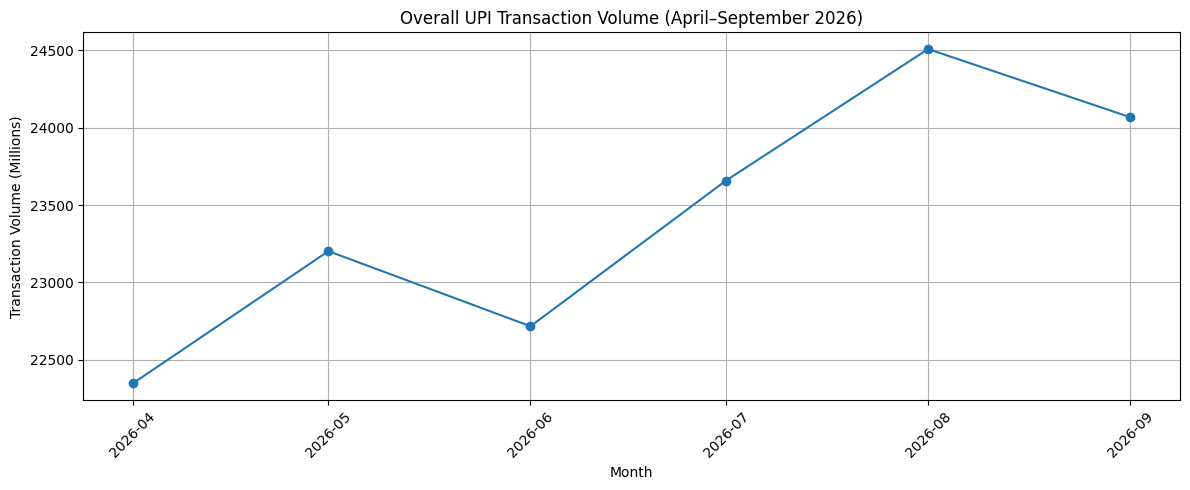

In [116]:
plt.figure(figsize=(12, 5))

plt.plot(
    overall_df["Month"],
    overall_df["Volume (In Mn.)"],
    marker="o"
)

plt.title("Overall UPI Transaction Volume (April–September 2026)")
plt.xlabel("Month")
plt.ylabel("Transaction Volume (Millions)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

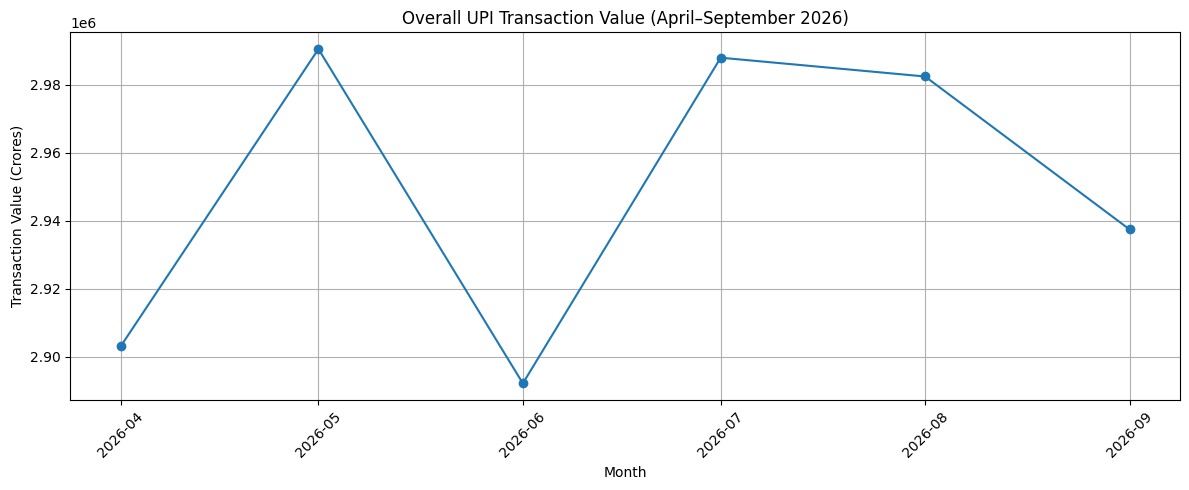

In [117]:
plt.figure(figsize=(12, 5))

plt.plot(
    overall_df["Month"],
    overall_df["Value (In Cr.)"],
    marker="o"
)

plt.title("Overall UPI Transaction Value (April–September 2026)")
plt.xlabel("Month")
plt.ylabel("Transaction Value (Crores)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [118]:
# Calculate average transaction amount in rupees

overall_df["Average Transaction Amount (Rs.)"] = (
    overall_df["Value (In Cr.)"] * 10_000_000
) / (
    overall_df["Volume (In Mn.)"] * 1_000_000
)

display(
    overall_df[
        ["Month", "Average Transaction Amount (Rs.)"]
    ].round(2)
)

,Month,Average Transaction Amount (Rs.)
0,2026-04-01,1299.06
1,2026-05-01,1288.87
2,2026-06-01,1273.17
3,2026-07-01,1262.93
4,2026-08-01,1216.84
5,2026-09-01,1220.44


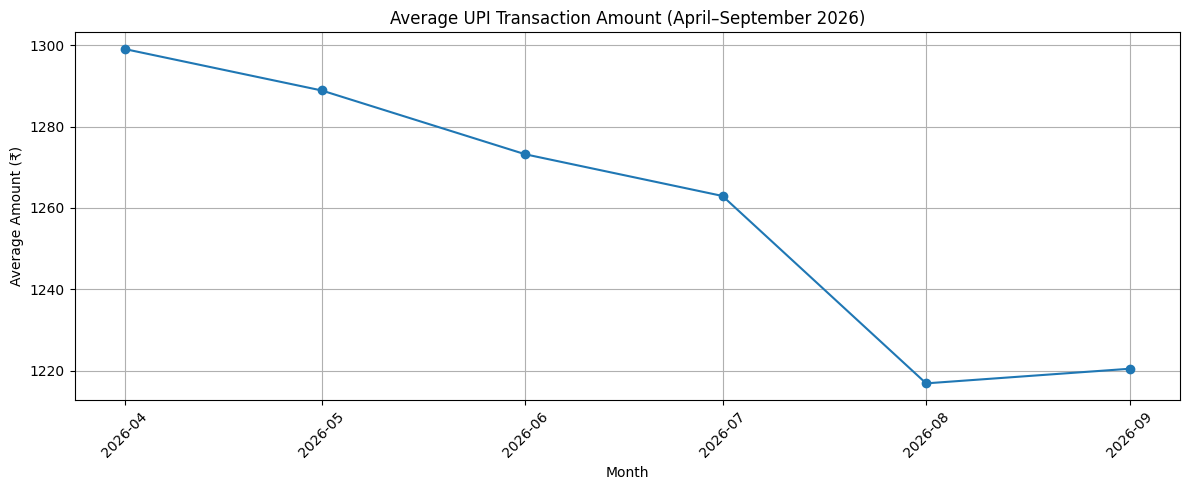

In [119]:
plt.figure(figsize=(12, 5))

plt.plot(
    overall_df["Month"],
    overall_df["Average Transaction Amount (Rs.)"],
    marker="o"
)

plt.title("Average UPI Transaction Amount (April–September 2026)")
plt.xlabel("Month")
plt.ylabel("Average Amount (₹)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

## 4. State-wise UPI Analysis

In [120]:
from google.colab import files

uploaded_state = files.upload()

Saving npci-upi-states.csv to npci-upi-states (1).csv


In [121]:
# Load the state-wise UPI CSV
state_df = pd.read_csv(next(iter(uploaded_state)))

# Check dataset size
print("Dataset shape:", state_df.shape)

# Check column names
print("\nColumn names:")
print(state_df.columns.tolist())

# Check data types
print("\nDataset information:")
state_df.info()

# Display first 10 rows
display(state_df.head(10))

Dataset shape: (42, 149)

Column names:
['date', 'Andaman and Nicobar Islands, share of all UPI value, % (as printed)', 'Andaman and Nicobar Islands, value', 'Andaman and Nicobar Islands, share of all UPI transactions, % (as printed)', 'Andaman and Nicobar Islands, number of transactions', 'Andhra Pradesh, share of all UPI value, % (as printed)', 'Andhra Pradesh, value', 'Andhra Pradesh, share of all UPI transactions, % (as printed)', 'Andhra Pradesh, number of transactions', 'Arunachal Pradesh, share of all UPI value, % (as printed)', 'Arunachal Pradesh, value', 'Arunachal Pradesh, share of all UPI transactions, % (as printed)', 'Arunachal Pradesh, number of transactions', 'Assam, share of all UPI value, % (as printed)', 'Assam, value', 'Assam, share of all UPI transactions, % (as printed)', 'Assam, number of transactions', 'Bihar, share of all UPI value, % (as printed)', 'Bihar, value', 'Bihar, share of all UPI transactions, % (as printed)', 'Bihar, number of transactions', 'Chandiga

,date,"Andaman and Nicobar Islands, share of all UPI value, % (as printed)","Andaman and Nicobar Islands, value","Andaman and Nicobar Islands, share of all UPI transactions, % (as printed)","Andaman and Nicobar Islands, number of transactions","Andhra Pradesh, share of all UPI value, % (as printed)","Andhra Pradesh, value","Andhra Pradesh, share of all UPI transactions, % (as printed)","Andhra Pradesh, number of transactions","Arunachal Pradesh, share of all UPI value, % (as printed)",...,"Uttar Pradesh, share of all UPI transactions, % (as printed)","Uttar Pradesh, number of transactions","Uttarakhand, share of all UPI value, % (as printed)","Uttarakhand, value","Uttarakhand, share of all UPI transactions, % (as printed)","Uttarakhand, number of transactions","West Bengal, share of all UPI value, % (as printed)","West Bengal, value","West Bengal, share of all UPI transactions, % (as printed)","West Bengal, number of transactions"
0,2023-04-01,0.02,3344900000,0.02,1600000,4.20,594440500000,3.16,279960000,0.09,...,6.43,569780000,0.78,110915800000,0.89,79240000,3.10,439220500000,2.63,233460000
1,2023-05-01,0.02,3363000000,0.02,1660000,4.36,649863800000,3.19,300200000,0.09,...,6.51,612760000,0.81,119948400000,0.91,85320000,3.24,482334400000,2.80,263520000
2,2023-06-01,0.02,3059100000,0.02,1560000,4.27,629769900000,3.16,295260000,0.09,...,6.39,596110000,0.77,113840600000,0.85,79350000,3.36,496035500000,2.93,273830000
3,2023-07-01,0.02,3187300000,0.02,1690000,4.37,670848600000,3.24,323270000,0.09,...,6.33,630300000,0.70,107853500000,0.79,78540000,3.27,501121500000,2.91,289590000
4,2023-08-01,0.02,3388800000,0.02,1840000,4.43,699098500000,3.30,349580000,0.09,...,6.41,678370000,0.68,107066600000,0.77,81710000,3.10,488194400000,2.70,286090000
5,2023-09-01,0.02,3478700000,0.02,1870000,4.25,671781100000,3.19,336990000,0.09,...,6.45,680360000,0.70,110106900000,0.79,83190000,3.08,487075500000,2.66,280300000
6,2023-10-01,0.02,3968700000,0.02,2110000,4.19,719419500000,3.17,361830000,0.09,...,6.60,752990000,0.77,131325900000,0.84,96060000,3.19,546776800000,2.82,321250000
7,2023-11-01,0.02,4276200000,0.02,2220000,4.26,740544200000,3.35,376190000,0.10,...,7.00,786830000,0.74,128691900000,0.80,90040000,3.09,537538000000,2.79,312970000
8,2023-12-01,0.03,4911800000,0.02,2640000,4.62,841499900000,3.64,437750000,0.11,...,6.44,774150000,0.62,113773100000,0.69,82740000,2.92,532167800000,2.53,303960000
9,2024-01-01,0.03,4935100000,0.02,2650000,4.90,902969400000,3.81,465480000,0.10,...,6.73,821190000,0.64,117830300000,0.70,85680000,3.14,578769000000,2.74,334000000


In [122]:
# Check data quality
print("Duplicate rows:", state_df.duplicated().sum())

print("\nMissing values:", state_df.isnull().sum().sum())

print("\nDate column information:")
print(state_df["date"].dtype)

# Convert date into datetime format
state_df["date"] = pd.to_datetime(
    state_df["date"], errors="coerce"
)

print("\nDate range:")
print(state_df["date"].min(), "to", state_df["date"].max())

print("\nFirst 5 dates:")
print(state_df["date"].head())

Duplicate rows: 0

Missing values: 111

Date column information:
object

Date range:
2023-04-01 00:00:00 to 2026-09-01 00:00:00

First 5 dates:
0   2023-04-01
1   2023-05-01
2   2023-06-01
3   2023-07-01
4   2023-08-01
Name: date, dtype: datetime64[ns]


In [123]:
# Find columns containing missing values
missing_columns = state_df.isnull().sum()

missing_columns = missing_columns[missing_columns > 0]

print("Columns with missing values:")
display(missing_columns.sort_values(ascending=False))

print("\nTotal columns with missing values:",
      len(missing_columns))

print("\nTotal missing values:",
      missing_columns.sum())

Columns with missing values:


,0
"Not assigned to a state (NPCI's 'Unclassified'), share of all UPI value, % (as printed)",3
"Not assigned to a state (NPCI's 'Unclassified'), share of all UPI transactions, % (as printed)",3
"Andhra Pradesh, share of all UPI transactions, % (as printed)",2
"Andhra Pradesh, share of all UPI value, % (as printed)",2
"Bihar, share of all UPI transactions, % (as printed)",2
...,...
"Sikkim, share of all UPI value, % (as printed)",1
"Tripura, share of all UPI transactions, % (as printed)",1
"Tripura, share of all UPI value, % (as printed)",1
"Uttarakhand, share of all UPI transactions, % (as printed)",1



Total columns with missing values: 72

Total missing values: 111


In [124]:
# Display all column names
for i, col in enumerate(state_df.columns):
    print(i, ":", col)

0 : date
1 : Andaman and Nicobar Islands, share of all UPI value, % (as printed)
2 : Andaman and Nicobar Islands, value
3 : Andaman and Nicobar Islands, share of all UPI transactions, % (as printed)
4 : Andaman and Nicobar Islands, number of transactions
5 : Andhra Pradesh, share of all UPI value, % (as printed)
6 : Andhra Pradesh, value
7 : Andhra Pradesh, share of all UPI transactions, % (as printed)
8 : Andhra Pradesh, number of transactions
9 : Arunachal Pradesh, share of all UPI value, % (as printed)
10 : Arunachal Pradesh, value
11 : Arunachal Pradesh, share of all UPI transactions, % (as printed)
12 : Arunachal Pradesh, number of transactions
13 : Assam, share of all UPI value, % (as printed)
14 : Assam, value
15 : Assam, share of all UPI transactions, % (as printed)
16 : Assam, number of transactions
17 : Bihar, share of all UPI value, % (as printed)
18 : Bihar, value
19 : Bihar, share of all UPI transactions, % (as printed)
20 : Bihar, number of transactions
21 : Chandigarh, s

In [125]:
# Correctly identify states and their metrics

metrics = [
    "share of all UPI value, % (as printed)",
    "share of all UPI transactions, % (as printed)",
    "number of transactions",
    "value"
]

state_data = []

for col in state_df.columns:
    if col == "date":
        continue

    for metric in metrics:
        suffix = ", " + metric

        if col.endswith(suffix):
            state = col[:-len(suffix)]

            state_data.append({
                "state": state,
                "metric": metric,
                "column": col
            })
            break

state_long = pd.DataFrame(state_data)

print("Unique geographical categories:",
      state_long["state"].nunique())

print("\nMetrics found:")
print(state_long["metric"].unique())

print("\nFirst 12 mappings:")
display(state_long.head(12))

Unique geographical categories: 37

Metrics found:
['share of all UPI value, % (as printed)' 'value'
 'share of all UPI transactions, % (as printed)' 'number of transactions']

First 12 mappings:


,state,metric,column
0,Andaman and Nicobar Islands,"share of all UPI value, % (as printed)","Andaman and Nicobar Islands, share of all UPI ..."
1,Andaman and Nicobar Islands,value,"Andaman and Nicobar Islands, value"
2,Andaman and Nicobar Islands,"share of all UPI transactions, % (as printed)","Andaman and Nicobar Islands, share of all UPI ..."
3,Andaman and Nicobar Islands,number of transactions,"Andaman and Nicobar Islands, number of transac..."
4,Andhra Pradesh,"share of all UPI value, % (as printed)","Andhra Pradesh, share of all UPI value, % (as ..."
5,Andhra Pradesh,value,"Andhra Pradesh, value"
6,Andhra Pradesh,"share of all UPI transactions, % (as printed)","Andhra Pradesh, share of all UPI transactions,..."
7,Andhra Pradesh,number of transactions,"Andhra Pradesh, number of transactions"
8,Arunachal Pradesh,"share of all UPI value, % (as printed)","Arunachal Pradesh, share of all UPI value, % (..."
9,Arunachal Pradesh,value,"Arunachal Pradesh, value"


In [126]:
# Create a clean state-wise dataset

state_records = []

for state in state_long["state"].unique():

    state_columns = state_long[
        state_long["state"] == state
    ].set_index("metric")["column"]

    temp = pd.DataFrame({
        "date": state_df["date"],
        "state": state,
        "transactions": state_df[
            state_columns["number of transactions"]
        ],
        "transaction_value": state_df[
            state_columns["value"]
        ],
        "transaction_share_pct": state_df[
            state_columns["share of all UPI transactions, % (as printed)"]
        ],
        "value_share_pct": state_df[
            state_columns["share of all UPI value, % (as printed)"]
        ]
    })

    state_records.append(temp)

state_analysis = pd.concat(
    state_records,
    ignore_index=True
)

print("Final dataset shape:", state_analysis.shape)

print("\nFirst 10 rows:")
display(state_analysis.head(10))

print("\nMissing values:")
print(state_analysis.isnull().sum())

Final dataset shape: (1554, 6)

First 10 rows:


,date,state,transactions,transaction_value,transaction_share_pct,value_share_pct
0,2023-04-01,Andaman and Nicobar Islands,1600000,3344900000,0.02,0.02
1,2023-05-01,Andaman and Nicobar Islands,1660000,3363000000,0.02,0.02
2,2023-06-01,Andaman and Nicobar Islands,1560000,3059100000,0.02,0.02
3,2023-07-01,Andaman and Nicobar Islands,1690000,3187300000,0.02,0.02
4,2023-08-01,Andaman and Nicobar Islands,1840000,3388800000,0.02,0.02
5,2023-09-01,Andaman and Nicobar Islands,1870000,3478700000,0.02,0.02
6,2023-10-01,Andaman and Nicobar Islands,2110000,3968700000,0.02,0.02
7,2023-11-01,Andaman and Nicobar Islands,2220000,4276200000,0.02,0.02
8,2023-12-01,Andaman and Nicobar Islands,2640000,4911800000,0.02,0.03
9,2024-01-01,Andaman and Nicobar Islands,2650000,4935100000,0.02,0.03



Missing values:
date                      0
state                     0
transactions              0
transaction_value         0
transaction_share_pct    55
value_share_pct          56
dtype: int64


In [127]:
# Separate Unclassified data from states and UTs

unclassified_data = state_analysis[
    state_analysis["state"].str.contains(
        "Unclassified", case=False, na=False
    )
].copy()

state_analysis_clean = state_analysis[
    ~state_analysis["state"].str.contains(
        "Unclassified", case=False, na=False
    )
].copy()

print("State and UT dataset shape:",
      state_analysis_clean.shape)

print("\nUnclassified dataset shape:",
      unclassified_data.shape)

print("\nNumber of states and UTs:",
      state_analysis_clean["state"].nunique())

print("\nDate range:",
      state_analysis_clean["date"].min(),
      "to",
      state_analysis_clean["date"].max())

State and UT dataset shape: (1512, 6)

Unclassified dataset shape: (42, 6)

Number of states and UTs: 36

Date range: 2023-04-01 00:00:00 to 2026-09-01 00:00:00


In [128]:
# Total UPI transactions by state/UT
state_transaction_ranking = (
    state_analysis_clean
    .groupby("state")["transactions"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

state_transaction_ranking.columns = [
    "State/UT",
    "Total Transactions"
]

print("Top 10 States/UTs by UPI Transaction Volume:")

display(state_transaction_ranking.head(10))

Top 10 States/UTs by UPI Transaction Volume:


,State/UT,Total Transactions
0,Maharashtra,86475469330
1,Karnataka,45904814021
2,Uttar Pradesh,41710810927
3,Telangana,35326746205
4,Tamil Nadu,29915573029
5,Rajasthan,22866193660
6,Andhra Pradesh,21954950727
7,Madhya Pradesh,20725391401
8,Gujarat,19444867591
9,Delhi,19442285421


In [129]:
# Total UPI transaction value by state/UT

state_value_ranking = (
    state_analysis_clean
    .groupby("state")["transaction_value"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

state_value_ranking.columns = [
    "State/UT",
    "Total Transaction Value"
]

print("Top 10 States/UTs by UPI Transaction Value:")

display(state_value_ranking.head(10))

Top 10 States/UTs by UPI Transaction Value:


,State/UT,Total Transaction Value
0,Maharashtra,108630422809623
1,Karnataka,63866362962025
2,Telangana,57095742485863
3,Uttar Pradesh,56397224392276
4,Tamil Nadu,46705063040165
5,Andhra Pradesh,39277964095699
6,Rajasthan,34553331553428
7,Gujarat,29885081227237
8,Madhya Pradesh,28050595740460
9,Bihar,27313307978001


In [130]:
# Calculate average transaction amount by state/UT

state_average_amount = (
    state_analysis_clean
    .groupby("state")
    .agg(
        total_transactions=("transactions", "sum"),
        total_value=("transaction_value", "sum")
    )
    .reset_index()
)

state_average_amount["average_transaction_amount"] = (
    state_average_amount["total_value"] /
    state_average_amount["total_transactions"]
)

state_average_amount = state_average_amount.sort_values(
    "average_transaction_amount",
    ascending=False
)

print("Top 10 States/UTs by Average Transaction Amount:")

display(state_average_amount.head(10))

Top 10 States/UTs by Average Transaction Amount:


,state,total_transactions,total_value,average_transaction_amount
21,Manipur,462011993,996093796179,2155.991211
17,Ladakh,132653057,254531613294,1918.776838
1,Andhra Pradesh,21954950727,39277964095699,1789.025381
27,Punjab,8099411352,13861511675809,1711.422111
24,Nagaland,415220355,704554391010,1696.820453
0,Andaman and Nicobar Islands,139169840,229955816658,1652.339448
23,Mizoram,396753434,648014573949,1633.292918
31,Telangana,35326746205,57095742485863,1616.218549
30,Tamil Nadu,29915573029,46705063040165,1561.229096
35,West Bengal,17411876149,27072594782823,1554.835019


In [131]:
# Calculate transaction growth by state

state_growth = (
    state_analysis_clean
    .sort_values("date")
    .groupby("state")
    .agg(
        first_month=("transactions", "first"),
        last_month=("transactions", "last")
    )
    .reset_index()
)

state_growth["growth_pct"] = (
    (state_growth["last_month"] -
     state_growth["first_month"])
    / state_growth["first_month"]
) * 100

state_growth = state_growth.sort_values(
    "growth_pct", ascending=False
)

print("Top 10 States/UTs by Transaction Growth:")

display(state_growth.head(10))

Top 10 States/UTs by Transaction Growth:


,state,first_month,last_month,growth_pct
18,Lakshadweep,90000,752837,736.485556
23,Mizoram,3250000,16573138,409.942708
22,Meghalaya,4260000,20951807,391.826455
24,Nagaland,3640000,15464482,324.848407
2,Arunachal Pradesh,6620000,26862193,305.773308
17,Ladakh,1390000,5442605,291.554317
13,Jammu and Kashmir,28440000,105740418,271.801751
32,Tripura,5520000,18774876,240.124565
3,Assam,81020000,256571198,216.676374
29,Sikkim,3440000,10085791,193.191599


In [132]:
# Combine growth and transaction volume rankings

state_growth_analysis = state_growth.merge(
    state_transaction_ranking,
    left_on="state",
    right_on="State/UT"
)

state_growth_analysis = state_growth_analysis[
    [
        "state",
        "first_month",
        "last_month",
        "growth_pct",
        "Total Transactions"
    ]
].sort_values("growth_pct", ascending=False)

print("Growth and Transaction Volume Comparison:")

display(state_growth_analysis.head(15))

Growth and Transaction Volume Comparison:


,state,first_month,last_month,growth_pct,Total Transactions
0,Lakshadweep,90000,752837,736.485556,18701762
1,Mizoram,3250000,16573138,409.942708,396753434
2,Meghalaya,4260000,20951807,391.826455,518057273
3,Nagaland,3640000,15464482,324.848407,415220355
4,Arunachal Pradesh,6620000,26862193,305.773308,709201666
5,Ladakh,1390000,5442605,291.554317,132653057
6,Jammu and Kashmir,28440000,105740418,271.801751,2893547099
7,Tripura,5520000,18774876,240.124565,516556271
8,Assam,81020000,256571198,216.676374,7653498674
9,Sikkim,3440000,10085791,193.191599,291115601


In [133]:
# Combine growth and transaction volume data

opportunity_data = state_growth_analysis.copy()

# Calculate median values
median_volume = opportunity_data["Total Transactions"].median()
median_growth = opportunity_data["growth_pct"].median()

# Classify states into four business segments

def classify_market(row):

    if row["Total Transactions"] >= median_volume and row["growth_pct"] >= median_growth:
        return "High Volume - High Growth"

    elif row["Total Transactions"] >= median_volume and row["growth_pct"] < median_growth:
        return "High Volume - Lower Growth"

    elif row["Total Transactions"] < median_volume and row["growth_pct"] >= median_growth:
        return "Low Volume - High Growth"

    else:
        return "Low Volume - Lower Growth"

opportunity_data["Market Segment"] = opportunity_data.apply(
    classify_market, axis=1
)

print("Business Opportunity Segments:")

display(
    opportunity_data[
        ["state", "Total Transactions", "growth_pct", "Market Segment"]
    ].sort_values(
        ["Market Segment", "Total Transactions"],
        ascending=[True, False]
    )
)

print("\nNumber of states in each segment:")

display(
    opportunity_data["Market Segment"].value_counts()
)

Business Opportunity Segments:


,state,Total Transactions,growth_pct,Market Segment
15,Tamil Nadu,29915573029,124.844190,High Volume - High Growth
13,Andhra Pradesh,21954950727,134.767568,High Volume - High Growth
17,Gujarat,19444867591,118.966489,High Volume - High Growth
16,West Bengal,17411876149,123.652041,High Volume - High Growth
11,Kerala,14789726844,154.194972,High Volume - High Growth
8,Assam,7653498674,216.676374,High Volume - High Growth
35,Maharashtra,86475469330,27.138494,High Volume - Lower Growth
30,Karnataka,45904814021,61.410292,High Volume - Lower Growth
18,Uttar Pradesh,41710810927,118.687419,High Volume - Lower Growth
33,Telangana,35326746205,36.761487,High Volume - Lower Growth



Number of states in each segment:


,count
Market Segment,
Low Volume - High Growth,12
High Volume - Lower Growth,12
High Volume - High Growth,6
Low Volume - Lower Growth,6


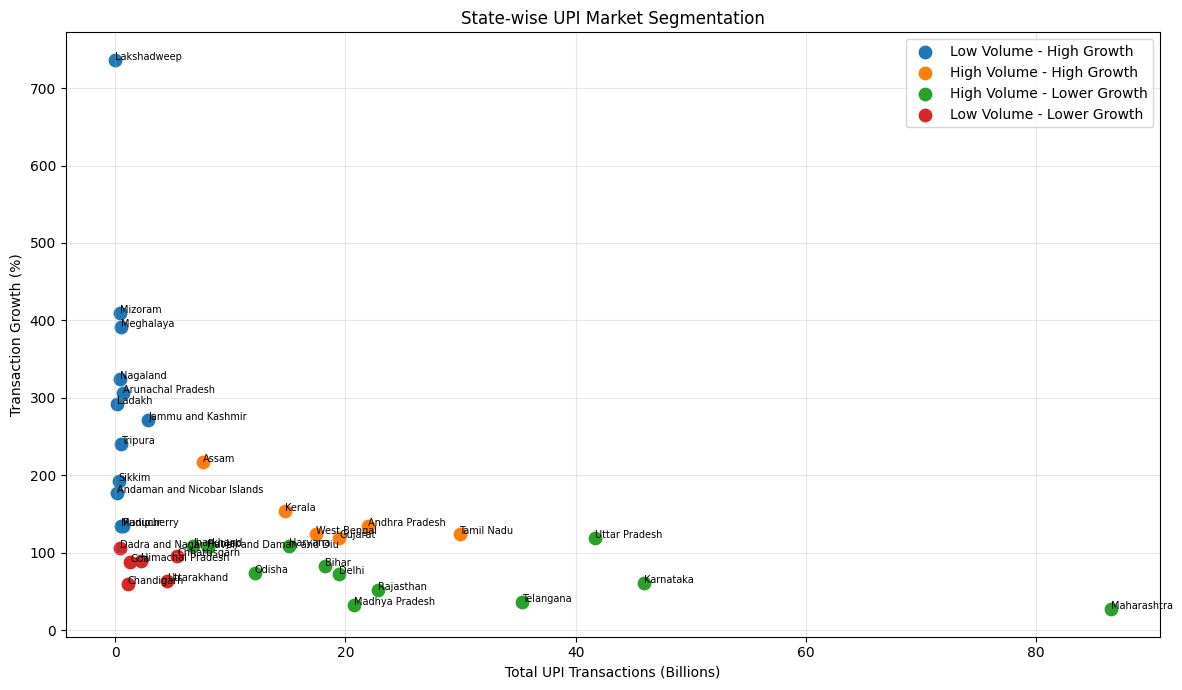

In [134]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))

for segment in opportunity_data["Market Segment"].unique():

    segment_data = opportunity_data[
        opportunity_data["Market Segment"] == segment
    ]

    plt.scatter(
        segment_data["Total Transactions"] / 1e9,
        segment_data["growth_pct"],
        label=segment,
        s=80
    )

    for _, row in segment_data.iterrows():
        plt.annotate(
            row["state"],
            (
                row["Total Transactions"] / 1e9,
                row["growth_pct"]
            ),
            fontsize=7
        )

plt.xlabel("Total UPI Transactions (Billions)")
plt.ylabel("Transaction Growth (%)")
plt.title("State-wise UPI Market Segmentation")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### State-wise UPI Market Segmentation: Key Findings

The state-wise analysis reveals differences in UPI transaction volume and growth across India.

The results show that some states have high transaction volumes and strong growth, while others have smaller transaction volumes but higher growth percentages.

States such as Uttar Pradesh, Karnataka, Andhra Pradesh, Tamil Nadu, and Assam represent important markets with substantial transaction activity and growth.

Smaller regions such as Lakshadweep, Mizoram, Meghalaya, and Nagaland show high percentage growth, suggesting potential opportunities for further market development.

Maharashtra and Telangana have high cumulative transaction volumes but comparatively lower growth rates.

**Business implication:** Payment companies should adopt different strategies for different market segments. Established markets may require stronger customer retention and merchant services, while emerging markets may benefit from improved payment acceptance and digital payment awareness.

These findings identify potential business opportunities, but further research would be required to understand the factors influencing regional UPI adoption.

## 5. Combined Business Insights

In [135]:
# Create a summary of our three analyses

business_summary = pd.DataFrame({
    "Analysis": [
        "Overall UPI Market",
        "App-wise Competition",
        "State-wise Market"
    ],
    "Key Finding": [
        "UPI transaction volume increased from June to August 2026, then declined slightly in September.",
        "PhonePe and Google Pay have the largest combined transaction volumes among the three selected apps.",
        "Maharashtra leads transaction volume, while Telangana ranks third in transaction value."
    ],
    "Business Focus": [
        "Understand market growth and transaction behavior.",
        "Study competition and app positioning.",
        "Identify established and emerging regional markets."
    ]
})

display(business_summary)

,Analysis,Key Finding,Business Focus
0,Overall UPI Market,UPI transaction volume increased from June to ...,Understand market growth and transaction behav...
1,App-wise Competition,PhonePe and Google Pay have the largest combin...,Study competition and app positioning.
2,State-wise Market,"Maharashtra leads transaction volume, while Te...",Identify established and emerging regional mar...


## 6. Business Recommendations

Based on the overall UPI market, app-wise competition, and state-wise analysis, the following business recommendations are proposed:

1. **Strengthen established markets:** Payment companies should focus on improving customer experience, merchant services, and customer retention in high-volume markets such as Maharashtra and Telangana.

2. **Explore emerging markets:** Regions such as Lakshadweep, Mizoram, and Meghalaya show high transaction growth percentages. Companies could investigate opportunities to expand merchant acceptance and improve digital payment awareness.

3. **Monitor app competition:** Payment companies should continuously monitor competitor performance, transaction trends, and their competitive positioning.

4. **Understand regional transaction behavior:** Differences in average transaction amounts across states can help businesses investigate regional payment patterns and merchant requirements.

5. **Track overall market trends:** Businesses should monitor transaction volume, transaction value, and average transaction amount to understand changes in UPI activity.

These recommendations are based on the observed dataset patterns. Further research would be needed to validate the causes of regional differences and estimate the commercial impact of these strategies.

## 7. Final Conclusion

## Conclusion

This project analyzed India's UPI ecosystem using three datasets: overall UPI statistics, app-wise transaction data, and state-wise UPI statistics.

The overall UPI analysis showed changes in transaction volume and transaction value between April and September 2026. Transaction volume reached its highest level in August 2026, while transaction value was highest in May 2026. The average transaction amount generally declined between April and August, followed by a small increase in September.

The app-wise analysis compared PhonePe, Google Pay, and Paytm using 31 common months from February 2024 to August 2026. PhonePe had the largest transaction share among these three selected apps, followed by Google Pay and Paytm. This comparison provides insight into competition among the selected apps, but it does not represent the entire UPI market.

The state-wise analysis covered 36 states and union territories from April 2023 to September 2026. Maharashtra recorded the highest cumulative transaction volume and transaction value. Telangana also showed a strong position, ranking fourth in transaction volume and third in transaction value.

The growth analysis highlighted emerging markets such as Lakshadweep, Mizoram, and Meghalaya, which recorded high percentage growth from April 2023 to September 2026. These regions may offer opportunities for further investigation into digital payment adoption and merchant acceptance.

Overall, the findings show that India's UPI ecosystem has different market characteristics across payment apps and geographical regions. Established markets offer opportunities to strengthen existing services, while emerging markets may offer opportunities for further expansion.

This project demonstrates how Python, Pandas, and Matplotlib can be used to clean data, analyze transaction trends, compare markets, and develop data-driven business recommendations.

## 8. Project Limitations

1. The overall UPI dataset used in this analysis covers only six months, from April to September 2026. Therefore, it is not sufficient to establish long-term trends or seasonality.

2. The app-wise comparison focuses on PhonePe, Google Pay, and Paytm. The calculated shares represent only these three selected apps, not the entire UPI market.

3. The app-wise dataset contains missing values, particularly for Paytm. The comparison uses common reporting months to maintain consistency.

4. The state-wise analysis covers 42 months, from April 2023 to September 2026. Missing percentage-share values were retained rather than automatically replaced with zero.

5. Transaction growth is calculated by comparing the first and last months in the available state-wise dataset. It is not an annual growth rate or CAGR.

6. The analysis identifies patterns and potential business opportunities but does not establish the causes of regional differences in UPI adoption.

7. The findings depend on the accuracy, completeness, and definitions provided in the original datasets.